# Module 1 · Partie 8 : Synthèse, pipeline généralisé et aide-mémoire

Ce dernier notebook **rassemble tout le module 1** : on y revoit les idées clés, on transforme les scripts du cours en **fonctions réutilisables** applicables à n'importe quel jeu de données, puis on termine par un aide-mémoire et un quiz de révision.

**Objectifs**
- Avoir une vue d'ensemble du module : quel problème motive chaque méthode ?
- Disposer d'un formulaire complet.
- Savoir écrire un **pipeline d'analyse générique** (contrôle des données → régression → résidus → sélection → pénalisation) et l'appliquer à un nouveau jeu de données.
- Se préparer à l'examen (*open course*, sans LM, 4 h, script + rapport).

**Prérequis** : parties 0 à 7.

**Sommaire**
1. Vue d'ensemble du module
2. Formulaire
3. Pipeline généralisé (fonctions réutilisables)
4. Application du pipeline à deux jeux de données
5. Aide-mémoire des fonctions R
6. Pièges fréquents
7. Quiz de révision
8. Préparer l'examen

In [1]:
suppressPackageStartupMessages({
  library(MASS)      # stepAIC
  library(glmnet)    # Ridge, Lasso, Elastic Net
  library(knitr)     # kable
})
options(repr.plot.width = 10, repr.plot.height = 6)

## 8.1 Vue d'ensemble du module

Le module suit le **processus KDD** (*Knowledge Discovery in Databases*) : objectif → sélection → nettoyage → transformation → modélisation (**calibration**) → interprétation et évaluation (**validation**).

Chaque méthode du module répond à un **problème** rencontré à l'étape précédente :

| Étape | Problème rencontré | Réponse vue dans le cours | Partie |
|---|---|---|---|
| Contrôle des données | Valeurs aberrantes, manquantes, variables à des échelles différentes | Statistiques descriptives, boxplot, comparaison avec la littérature, *scaling* | 1 |
| Distribution de *y* | Distribution asymétrique (lactoférrine) | Transformation `log10` ou `sqrt` | 1, 2 |
| 1 060 variables explicatives | Lesquelles utiliser ? | Corrélation *x*–*y* → régression univariée | 2 |
| Résidus non normaux ou hétéroscédastiques | Hypothèses de la régression violées | Analyse des résidus, transformation de *y*, distance de Cook | 2 |
| Une seule variable, c'est trop restrictif | L'information est répartie sur plusieurs variables | Régression multivariée (MCO) | 3 |
| Coefficients non significatifs, interprétation instable | **Colinéarité** | Sélection de variables (toutes les combinaisons, backward, forward, stepwise) | 3, 4 |
| $(X'X)^{-1}$ difficile ou impossible à inverser | Colinéarité, $p > n$ | Estimation numérique (descente de gradient) | 5 |
| Trop de variables : surapprentissage | Le modèle ne se généralise pas | Régressions pénalisées : Ridge, Lasso, Elastic Net | 6 |

> **Complément** : le fil rouge du module, c'est le **compromis ajustement / généralisation**. Ajouter des variables améliore toujours l'ajustement sur les données de calibration (R² ↑), mais pas forcément les prédictions sur de nouvelles données. Le R² ajusté, l'AIC, la sélection de variables et la pénalisation sont autant de façons de **pénaliser la complexité**. La validation proprement dite (jeu indépendant, validation croisée) est le sujet du module 2.

## 8.2 Formulaire

### Statistiques descriptives
| Paramètre | Formule | R |
|---|---|---|
| Moyenne | $\bar x = \frac{1}{n}\sum x_i$ | `mean(x)` |
| Médiane | $x_{[(n+1)/2]}$ si *n* impair, $\frac{x_{[n/2]}+x_{[n/2+1]}}{2}$ si *n* pair | `median(x)` |
| Variance | $s^2 = \frac{1}{n}\sum (x_i-\bar x)^2$ (syllabus) ; R utilise $\frac{1}{n-1}$ | `var(x)` |
| Écart-type | $s = \sqrt{s^2}$ | `sd(x)` |
| Coefficient de variation | $cv = s/\bar x$ (souvent en %) | `sd(x)/mean(x)*100` |
| Étendue | $w = x_{[n]} - x_{[1]}$ | `diff(range(x))` |
| Écart interquartile | $q_3 - q_1$ | `IQR(x)` |
| Autoscaling | $x' = (x-\bar x)/\sigma_x$ | `scale(x)` |
| Min-max | $x' = (x-x_{min})/(x_{max}-x_{min})$ | `(x-min(x))/(max(x)-min(x))` |

### Régression univariée $y_i = a + b x_i + e_i$
$$b = \frac{cov(x,y)}{s_x^2} = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2} \qquad a = \bar y - b\,\bar x \qquad r = \frac{cov(x,y)}{s_x s_y}$$
$$MSE = \frac{1}{n}\sum e_i^2 = s_y^2(1-r^2) \qquad RMSE = \sqrt{MSE}, \quad 0 \le RMSE \le s_y$$

### Régression multivariée $y = X\beta + e$
$$\hat\beta = (X'X)^{-1}X'y \qquad MSE = \frac{1}{n-p}\sum e_i^2 \qquad R^2_{adj} = 1-\frac{(1-R^2)(n-1)}{n-k-1}$$
$$SEP = \sqrt{\frac{\sum (\hat y_i - y_i)^2}{\text{ddl résiduels}}} \quad (= \texttt{summary(mod)\$sigma})$$

### Descente de gradient
$$\beta_j \leftarrow \beta_j - \alpha\,\frac{\partial J}{\partial \beta_j} \quad\text{(mise à jour simultanée)} \qquad \nabla J = -\frac{2}{n}X'(y - X\beta)$$

### Régressions pénalisées
$$\text{Ridge : } \min \sum_i\Big(y_i - \sum_j \beta_j x_{ij}\Big)^2 + \lambda\sum_j \beta_j^2 \qquad \text{Lasso : } \min \sum_i\Big(y_i - \sum_j \beta_j x_{ij}\Big)^2 + \lambda\sum_j |\beta_j|$$
$$\text{Elastic Net : } \min \sum_i\Big(y_i - \sum_j \beta_j x_{ij}\Big)^2 + \lambda_2\sum_j \beta_j^2 + \lambda_1\sum_j |\beta_j|$$
$$\text{glmnet : } \min_{\beta_0,\beta}\ \frac{1}{N}\sum_{i=1}^N w_i\, l(y_i, \beta_0+\beta^T x_i) + \lambda\Big[(1-\alpha)\tfrac{\|\beta\|_2^2}{2} + \alpha\|\beta\|_1\Big] \quad (\alpha=0 \text{ Ridge}, \ \alpha=1 \text{ Lasso})$$

## 8.3 Pipeline généralisé : des scripts aux fonctions

Dans les scripts du cours (`training.R`, `homework1.R`, la résolution), les mêmes étapes sont **réécrites à la main** pour chaque jeu de données, avec des indices « en dur » (`[,2:1062]`, `+1`, `+4`, `[1051:1060]`…). C'est la principale source d'erreurs. On va encapsuler chaque étape dans une **fonction** qui prend en entrée une matrice `X` et un vecteur `y`, quel que soit le fichier d'origine.

> **Définition** : une fonction R se définit par `nom <- function(arguments, argument_optionnel = valeur_par_defaut) { corps ; valeur_renvoyée }`. La dernière expression évaluée est renvoyée (ou `return(...)`).

### Étape 1 : statistiques descriptives

In [2]:
# Statistiques descriptives d'une variable quantitative (position + dispersion)
stats_descriptives <- function(v) {
  q <- quantile(v, c(0.25, 0.5, 0.75))
  c(n = length(v), moyenne = mean(v), mediane = unname(q[2]),
    Q1 = unname(q[1]), Q3 = unname(q[3]), min = min(v), max = max(v),
    variance = var(v), ecart_type = sd(v), CV_pct = sd(v) / mean(v) * 100,
    etendue = diff(range(v)), IQR = IQR(v))
}

# Repérage simple des valeurs suspectes : règle des 3 sigma et règle du boxplot (1.5 IQR)
valeurs_suspectes <- function(v) {
  q <- quantile(v, c(0.25, 0.75)); iqr <- diff(q)
  list(regle_3sigma = which(abs(v - mean(v)) > 3 * sd(v)),
       regle_boxplot = which(v < q[1] - 1.5 * iqr | v > q[2] + 1.5 * iqr))
}

### Étape 2 : corrélations et choix des variables les plus corrélées

On remplace la construction de la matrice de corrélation complète (1061 × 1061, comme dans le cours) par `cor(X, y)` qui ne calcule **que** les 1060 corrélations utiles, et on travaille avec les **noms** des colonnes plutôt qu'avec des décalages d'indices (`+1`, `+4`).

In [3]:
# Corrélation de chaque colonne de X avec y (vecteur nommé)
spectre_correlation <- function(X, y) {
  r <- as.vector(cor(X, y))
  names(r) <- colnames(X)
  r
}

# Noms des k variables les plus corrélées en valeur absolue (de la plus forte à la plus faible)
top_k <- function(r, k = 10) names(sort(abs(r), decreasing = TRUE))[1:k]

### Étape 3 : performances et analyse des résidus d'un modèle `lm`

La fonction `perf()` vient directement du homework ; `analyse_residus()` regroupe les vérifications de la partie 2 (4 graphes, Shapiro-Wilk, distance de Cook avec le seuil $4/n$).

In [4]:
# Indicateurs de performance d'un modèle lm (cf. homework1.R)
perf <- function(mod) {
  c(k     = length(coef(mod)) - 1,                       # nb de variables (sans l'intercept)
    R2    = summary(mod)$r.squared,
    adjR2 = summary(mod)$adj.r.squared,
    SEP   = sqrt(sum(resid(mod)^2) / mod$df.residual),   # = summary(mod)$sigma
    AIC   = AIC(mod))
}

# Analyse des résidus : graphes + test de normalité + observations influentes
analyse_residus <- function(mod, graphes = TRUE, seuil_cook = 4 / length(resid(mod))) {
  if (graphes) { op <- par(mfrow = c(2, 2)); plot(mod); par(op) }
  sw   <- shapiro.test(resid(mod))
  cook <- cooks.distance(mod)
  list(shapiro_W = unname(sw$statistic), shapiro_p = sw$p.value,
       normalite_ok = sw$p.value > 0.05,
       influentes = which(cook > seuil_cook), cook_max = max(cook))
}

### Étape 4 : sélection de variables

`stepAIC()` a besoin d'un modèle dont la formule contient les variables **par leur nom**. On construit donc un `data.frame` et la formule avec `reformulate()`, l'équivalent compact de `as.formula(paste(...))` vu en partie 4.

In [5]:
# Sélection backward / forward / both sur un sous-ensemble de variables
selection_step <- function(X, y, vars, direction = "backward") {
  d <- data.frame(y = y, X[, vars, drop = FALSE])
  complet <- lm(reformulate(vars, response = "y"), data = d)
  if (direction == "backward") {
    stepAIC(complet, direction = "backward", trace = 0)
  } else {
    vide <- lm(y ~ 1, data = d)   # même réponse que le modèle complet !
    stepAIC(vide, direction = direction, trace = 0,
            scope = list(upper = complet, lower = vide))
  }
}

### Étape 5 : régression pénalisée et choix de λ sur un jeu de validation

Le cours précise que λ se règle « par tests successifs » : on essaie une **grille** de valeurs et on garde celle qui donne la meilleure performance sur un **jeu de validation**. La fonction ci-dessous découpe les données (calibration / validation), ajuste `glmnet` sur la calibration et calcule l'erreur de prédiction (RMSEP) en validation pour chaque λ.

In [6]:
# Choix de lambda par validation simple (calibration / validation)
choisir_lambda <- function(X, y, alpha = 1, prop_calib = 0.7, seed = 1) {
  set.seed(seed)
  idx <- sample(seq_len(nrow(X)), size = round(prop_calib * nrow(X)))
  mod <- glmnet(X[idx, ], y[idx], alpha = alpha, family = "gaussian")   # grille de λ automatique
  pred <- predict(mod, newx = X[-idx, ], s = mod$lambda)                # une colonne par λ
  rmsep <- sqrt(colMeans((pred - y[-idx])^2))
  best <- which.min(rmsep)
  list(modele = mod, lambda = mod$lambda, rmsep = rmsep,
       lambda_opt = mod$lambda[best], rmsep_opt = unname(rmsep[best]),
       nb_variables = mod$df[best])
}

> **Attention** : ce découpage unique dépend du hasard (`seed`). La **validation croisée** (`cv.glmnet`) répète ce découpage plusieurs fois et donne un choix plus stable ; elle sera vue en détail au module 2.

## 8.4 Application du pipeline

### 8.4.1 Lactoférrine (le jeu de données du cours)

In [7]:
lacto <- read.table("../lactoferrin.csv", sep = ";")
X_lacto <- as.matrix(lacto[, 2:1061])   # spectre : 1060 points (V2 à V1061)
y_lacto <- lacto[, 1062]                # lactoférrine (mg/L)

round(stats_descriptives(y_lacto), 2)
str(valeurs_suspectes(y_lacto))

n    moyenne    mediane         Q1         Q3        min        max 
    178.00     206.75      90.47      44.85     222.85       7.69    2038.27 
  variance ecart_type     CV_pct    etendue        IQR 
  91019.55     301.69     145.93    2030.57     178.00

List of 2
 $ regle_3sigma : int [1:4] 81 113 119 120
 $ regle_boxplot: int [1:21] 33 57 77 78 81 82 83 84 86 91 ...


In [8]:
r_lacto <- spectre_correlation(X_lacto, y_lacto)
vars_lacto <- top_k(r_lacto, 10)
vars_lacto
round(r_lacto[vars_lacto], 2)

[1] "V713" "V712" "V714" "V711" "V715" "V209" "V710" "V716" "V679" "V608"

V713  V712  V714  V711  V715  V209  V710  V716  V679  V608 
 0.51  0.51  0.46  0.44  0.36  0.32  0.30  0.27 -0.23 -0.23

On retrouve bien les 10 variables de la résolution (V713, V712, V714, V711, V715, V209, V710, V716, V679, V608).

> **Complément** : la sélection backward ci-dessous garde V713, V712, V714, V711 et V715. Ce sont exactement les variables `x[,6]` à `x[,10]` de la résolution, où les colonnes étaient rangées par corrélation croissante. On retrouve d'ailleurs le même R² (0.389).

In [9]:
# Univarié brut vs log10, puis multivarié log10
d <- data.frame(y = y_lacto, X_lacto[, vars_lacto])
m_uni     <- lm(y ~ V713, data = d)
m_uni_log <- lm(log10(y) ~ V713, data = d)
m_multi   <- lm(reformulate(vars_lacto, response = "log10(y)"), data = d)
kable(rbind(univarie = perf(m_uni), univarie_log10 = perf(m_uni_log),
            multivarie_log10 = perf(m_multi)), digits = 4)



|                 |  k|     R2|  adjR2|      SEP|       AIC|
|:----------------|--:|------:|------:|--------:|---------:|
|univarie         |  1| 0.2623| 0.2581| 259.8590| 2488.5404|
|univarie_log10   |  1| 0.2840| 0.2799|   0.4176|  198.2524|
|multivarie_log10 | 10| 0.4007| 0.3649|   0.3922|  184.5745|

List of 5
 $ shapiro_W   : num 0.997
 $ shapiro_p   : num 0.978
 $ normalite_ok: logi TRUE
 $ influentes  : Named int [1:6] 20 57 108 113 114 120
  ..- attr(*, "names")= chr [1:6] "20" "57" "108" "113" ...
 $ cook_max    : num 0.0626


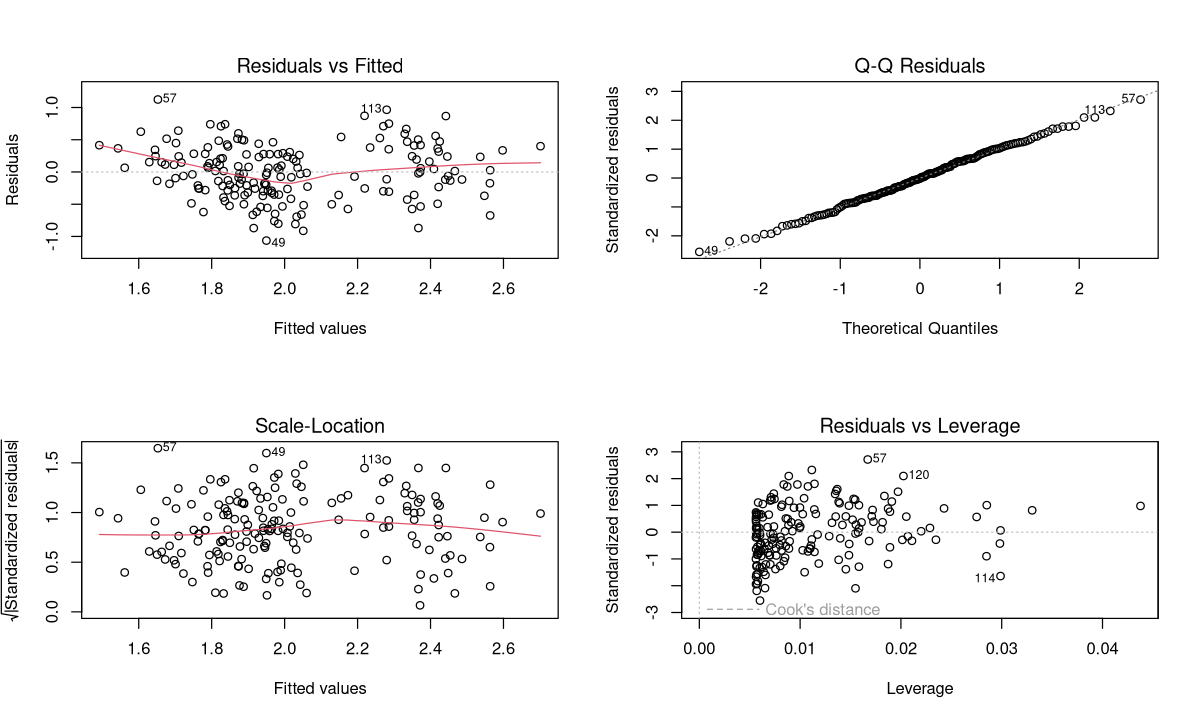

In [10]:
str(analyse_residus(m_uni_log))

In [11]:
# Sélection backward sur les 10 variables, avec log10(y)
m_back <- selection_step(X_lacto, log10(y_lacto), vars_lacto, "backward")
print(formula(m_back), showEnv = FALSE)
round(perf(m_back), 4)

y ~ V713 + V712 + V714 + V711 + V715


k       R2    adjR2      SEP      AIC 
  5.0000   0.3891   0.3713   0.3902 178.0031

lambda_opt        RMSEP nb_variables 
  0.01649634   0.37360160  39.00000000

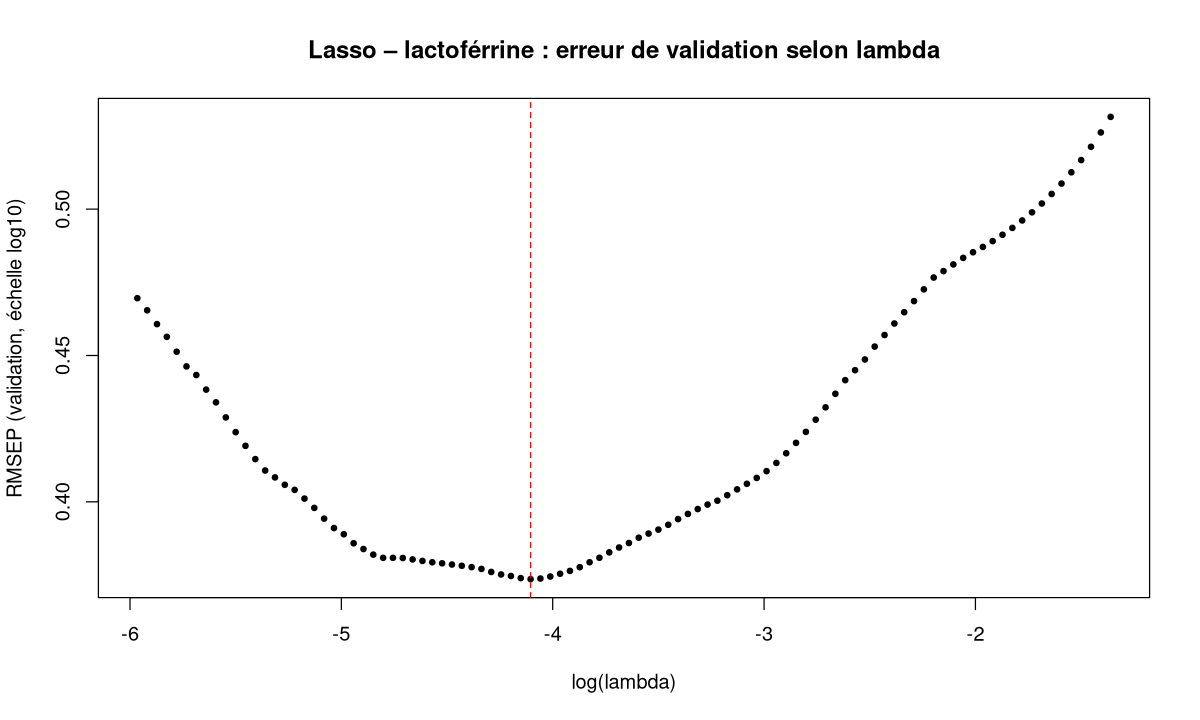

In [12]:
# Lasso sur le spectre complet, λ choisi en validation
res_lasso <- choisir_lambda(X_lacto, log10(y_lacto), alpha = 1)
c(lambda_opt = res_lasso$lambda_opt, RMSEP = res_lasso$rmsep_opt, nb_variables = res_lasso$nb_variables)
plot(log(res_lasso$lambda), res_lasso$rmsep, type = "b", pch = 19, cex = 0.6,
     xlab = "log(lambda)", ylab = "RMSEP (validation, échelle log10)",
     main = "Lasso – lactoférrine : erreur de validation selon lambda")
abline(v = log(res_lasso$lambda_opt), col = "red", lty = 2)

### 8.4.2 Même pipeline, autre jeu de données : acides gras mono-insaturés (MONO)

C'est tout l'intérêt de la généralisation : **aucun indice à recalculer**. Seules les deux lignes qui définissent `X` et `y` changent.

In [13]:
fa <- read.table("../Homework1/fatty_acids.csv", sep = ";", header = TRUE)
X_fa <- as.matrix(fa[, 5:1064])   # spectre (colonnes X1 à X1060)
y_fa <- fa$MONO                   # variable à expliquer : MONO

round(stats_descriptives(y_fa), 3)
vars_fa <- top_k(spectre_correlation(X_fa, y_fa), 10)
vars_fa

n    moyenne    mediane         Q1         Q3        min        max 
   485.000      1.087      1.019      0.803      1.295      0.071      2.617 
  variance ecart_type     CV_pct    etendue        IQR 
     0.163      0.404     37.191      2.546      0.492

[1] "X501" "X500" "X518" "X517" "X519" "X520" "X502" "X521" "X516" "X522"

In [14]:
d_fa <- data.frame(y = y_fa, X_fa[, vars_fa])
m_fa_uni   <- lm(reformulate(vars_fa[1], response = "y"), data = d_fa)
m_fa_multi <- lm(reformulate(vars_fa, response = "y"), data = d_fa)
m_fa_back  <- selection_step(X_fa, y_fa, vars_fa, "backward")
kable(rbind(univarie = perf(m_fa_uni), multivarie = perf(m_fa_multi),
            backward = perf(m_fa_back)), digits = 4)
str(analyse_residus(m_fa_back, graphes = FALSE))



|           |  k|     R2|  adjR2|    SEP|       AIC|
|:----------|--:|------:|------:|------:|---------:|
|univarie   |  1| 0.7409| 0.7403| 0.2060| -152.0183|
|multivarie | 10| 0.8337| 0.8302| 0.1666| -349.2726|
|backward   |  9| 0.8337| 0.8306| 0.1664| -351.2134|

List of 5
 $ shapiro_W   : num 0.957
 $ shapiro_p   : num 1.21e-10
 $ normalite_ok: logi FALSE
 $ influentes  : Named int [1:49] 3 5 10 13 19 24 25 27 32 36 ...
  ..- attr(*, "names")= chr [1:49] "3" "5" "10" "13" ...
 $ cook_max    : num 0.411


In [15]:
res_fa <- choisir_lambda(X_fa, y_fa, alpha = 1)
c(lambda_opt = res_fa$lambda_opt, RMSEP = res_fa$rmsep_opt, nb_variables = res_fa$nb_variables)

lambda_opt        RMSEP nb_variables 
 0.003577164  0.152184263 54.000000000

### Exercice 8.1 : Elastic Net sur MONO
Utilise `choisir_lambda()` avec `alpha = 0`, `0.5` puis `1` sur `X_fa`, `y_fa`. Rassemble dans un tableau le λ optimal, le RMSEP et le nombre de variables retenues. Quelle pénalité donne la plus petite erreur de validation ? Laquelle donne le modèle le plus parcimonieux ?

In [16]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
alphas <- c(0, 0.5, 1)
tab <- t(sapply(alphas, function(a) {
  r <- choisir_lambda(X_fa, y_fa, alpha = a)
  c(alpha = a, lambda_opt = r$lambda_opt, RMSEP = r$rmsep_opt, nb_variables = r$nb_variables)
}))
kable(tab, digits = 4)
```

Avec `alpha = 0` (Ridge), **toutes** les variables restent dans le modèle (1 060) : Ridge rétrécit les coefficients sans jamais les annuler. Avec `alpha = 0.5` et `alpha = 1`, une partie des coefficients est exactement nulle : c'est la sélection de variables propre au Lasso. En général, le Lasso donne le modèle le plus parcimonieux. Le meilleur RMSEP dépend des données et du découpage (`seed`), d'où l'intérêt de la validation croisée (module 2).

</details>

### Exercice 8.2 : ta propre fonction de rapport
Écris une fonction `rapport_modele(mod)` qui affiche en une fois : la formule du modèle, le tableau `perf(mod)`, la p-value de Shapiro-Wilk avec une phrase de conclusion (« résidus normaux » ou « résidus non normaux ») et les observations influentes. Teste-la sur `m_back`.

In [17]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
rapport_modele <- function(mod) {
  cat("Modèle :", deparse(formula(mod), width.cutoff = 500L), "\n\n")
  print(round(perf(mod), 4))
  a <- analyse_residus(mod, graphes = FALSE)
  cat("\nShapiro-Wilk : W =", round(a$shapiro_W, 4), "; p =", signif(a$shapiro_p, 3), "->",
      ifelse(a$normalite_ok, "résidus normaux (p > 0.05)", "résidus non normaux (p <= 0.05)"), "\n")
  cat("Observations influentes (Cook > 4/n) :", names(a$influentes), "\n")
  invisible(a)
}
rapport_modele(m_back)
```

`invisible()` renvoie le résultat sans l'afficher : pratique pour une fonction dont le rôle principal est d'imprimer quelque chose.

</details>

## 8.5 Aide-mémoire des fonctions R du module

| Catégorie | Fonction | Rôle |
|---|---|---|
| **Lecture** | `read.table(file, sep, header)` | Lire un fichier texte/CSV |
| | `str()`, `dim()`, `head()`, `names()` | Structure, dimensions, aperçu, noms |
| | `as.matrix()`, `data.frame()` | Conversion matrice / tableau de données |
| **Descriptif** | `summary()`, `mean()`, `median()`, `quantile()` | Position |
| | `var()`, `sd()`, `IQR()`, `range()`, `diff()` | Dispersion |
| | `summarytools::descr(y, transpose=TRUE)` | Tableau complet (Mean, Std.Dev, CV, Skewness…) |
| | `table()`, `prop.table()`, `cumsum()`, `cut()`, `addmargins()` | Variables qualitatives, tableaux de contingence |
| | `is.na()`, `complete.cases()` | Valeurs manquantes |
| | `scale()` | Autoscaling (centrer-réduire) |
| **Graphiques** | `hist(x, breaks, col, xlab, main)`, `boxplot()` | Distribution |
| | `plot(x, type="l")`, `par(mfrow=c(l,c))` | Courbes (spectres), mise en page |
| | `image()`, `corrplot::corrplot()` | Matrices de corrélation |
| **Corrélation** | `cor(X, y)`, `order()`, `sort()`, `which.max()` | Spectre de corrélation, classement |
| **Régression** | `lm(formule, data)`, `summary()`, `coef()`, `fitted()`, `resid()` | Ajustement MCO |
| | `predict(mod, newdata)`, `confint()`, `anova()` | Prédiction, intervalles, tests |
| | `solve()`, `t()`, `%*%`, `crossprod()` | MCO à la main : $(X'X)^{-1}X'y$ |
| **Résidus** | `plot(mod)`, `plot(mod, which=4)` | 4 graphes de diagnostic, distance de Cook |
| | `shapiro.test(resid(mod))`, `cooks.distance()` | Normalité, influence |
| **Sélection** | `paste0()`, `as.formula()`, `reformulate()` | Construire une formule |
| | `olsrr::ols_step_all_possible(mod)$result` | Toutes les combinaisons |
| | `MASS::stepAIC(mod, direction, scope, trace)` | Backward / forward / stepwise |
| | `relaimpo::calc.relimp()`, `boot.relimp()` | Importance relative des variables |
| **Pénalisée** | `glmnet(x, y, alpha, lambda, family, standardize)` | Ridge (α=0), Lasso (α=1), EN |
| | `plot(mod, xvar="lambda"/"norm")`, `coef(mod, s)`, `predict(mod, newx, s)` | Chemins, coefficients, prédictions |
| | `cv.glmnet()` | Choix de λ par validation croisée (module 2) |
| **Sauvegarde** | `save(obj, file=)`, `load(file)` | Sauver et recharger un modèle |

## 8.6 Pièges fréquents

1. **Décalage d'indices** : dans `lactoferrin.csv`, la variable spectrale *j* est dans la colonne *j + 1* (l'ID est en colonne 1) ; dans `fatty_acids.csv`, elle est dans la colonne *j + 4*. Travailler avec les **noms** (`colnames`) évite ces erreurs.
2. **`max(abs(r))` puis `r == cormax`** : si la corrélation la plus forte est **négative**, `r == cormax` ne trouve rien. Il faut comparer `abs(r) == cormax`, comme le fait le homework.
3. **Variance** : le syllabus définit $s^2$ avec $1/n$, alors que `var()` et `sd()` utilisent $1/(n-1)$. La différence est négligeable pour *n* grand.
4. **Transformation de *y*** : après `lm(log10(y) ~ x)`, les prédictions sont en log10. On revient à l'échelle d'origine avec `10^predict(...)`. Les R² et SEP de modèles en `y` et en `log10(y)` ne sont **pas directement comparables** (unités différentes).
5. **`stepAIC` forward/stepwise** : le modèle de départ (`lower`) et le modèle complet (`upper`) doivent avoir **la même réponse**. Partir de `lm(y ~ 1)` quand le modèle complet est en `log10(y)` fait travailler la sélection sur *y* brut (c'est ce qui se passe dans la résolution).
6. **AIC** : `stepAIC` utilise `extractAIC` ($n\log(RSS/n) + 2k$) alors que `AIC()` et `olsrr` utilisent la log-vraisemblance complète. Les valeurs diffèrent, mais le classement des modèles est le même.
7. **`glmnet`** attend une **matrice** (`as.matrix`) et non un `data.frame`. Il standardise par défaut (`standardize = TRUE`) et renvoie les coefficients à l'échelle d'origine.
8. **Séquence de λ** : il vaut mieux laisser `glmnet` choisir sa grille (décroissante). Si on la fournit, elle doit être décroissante.
9. **Échelle de λ** : `glmnet` divise la somme des carrés des résidus par $2n$. Un même λ n'a donc pas le même effet que dans la formule du cours.
10. **`pander()` dans Jupyter** affiche du Markdown brut : utiliser `kable()` ou `print()`.
11. **Colinéarité parfaite** (ex. acides gras dont la somme vaut 100 %) : `lm` renvoie `NA` pour un coefficient (« not defined because of singularities »).
12. **R² sur les données de calibration** : il augmente toujours quand on ajoute des variables. Comparer des modèles de tailles différentes avec le R² ajusté, l'AIC ou, mieux, un jeu de validation.

## 8.7 Quiz de révision

**Q1.** Une distribution présente *mode < médiane < moyenne*. Elle est :
a) symétrique  b) asymétrique à droite (queue vers les grandes valeurs)  c) asymétrique à gauche

<details>
<summary><b>Réponse</b></summary>

**b)** Les grandes valeurs tirent la moyenne vers la droite. C'est le cas de la lactoférrine (moyenne 206.7 > médiane 90.5), d'où la transformation log10.

</details>

**Q2.** Vrai ou faux : une valeur extrême est toujours une valeur aberrante (*outlier*).

<details>
<summary><b>Réponse</b></summary>

**Faux.** Une valeur extrême peut être réelle (ex. un lait de vache atteinte de mammite peut contenir jusqu'à 1 890 mg/L de lactoférrine). À l'inverse, une valeur aberrante (erreur d'encodage, de mesure) n'est pas forcément extrême. On vérifie l'origine et on compare avec la littérature.

</details>

**Q3.** Dans `summary(lm)`, que vaut `t value` et comment l'interpréter ?

<details>
<summary><b>Réponse</b></summary>

$t = \text{Estimate}/\text{Std. Error}$. Plus $|t|$ est grand, plus le coefficient est significativement différent de 0. La p-value `Pr(>|t|)` est la probabilité d'observer un *t* aussi extrême si le vrai coefficient était nul ; si elle est inférieure à 0.05, le coefficient est significatif.

</details>

**Q4.** Le test de Shapiro-Wilk sur les résidus donne p = 0.65. Conclusion ?

<details>
<summary><b>Réponse</b></summary>

p > 0.05 : on ne rejette pas H₀ (« les résidus suivent une loi normale »). La normalité des résidus est acceptée. Il faut encore vérifier l'homoscédasticité (graphes *Residuals vs Fitted* et *Scale-Location*).

</details>

**Q5.** Pourquoi, dans `reg2b` (10 variables spectrales), aucun coefficient n'est significatif alors que le R² est meilleur que celui du modèle univarié ?

<details>
<summary><b>Réponse</b></summary>

À cause de la **colinéarité** : des points spectraux adjacents portent la même information (corrélations jusqu'à 0.99). Les erreurs standard des coefficients explosent et chaque variable semble inutile « en présence des autres », alors que prise seule elle serait significative.

</details>

**Q6.** Que se passe-t-il en Ridge quand λ = 0 ? Et quand λ → ∞ ?

<details>
<summary><b>Réponse</b></summary>

λ = 0 : aucune pénalité, on retrouve la régression linéaire classique (MCO). λ → ∞ : la pénalité domine, tous les coefficients tendent vers 0 et le modèle se réduit à l'intercept (R² → 0).

</details>

**Q7.** Quelle méthode met des coefficients **exactement** à zéro : Ridge ou Lasso ? Quelle conséquence pratique ?

<details>
<summary><b>Réponse</b></summary>

Le **Lasso** (pénalité L1). Il réalise donc une **sélection automatique de variables**. Attention : face à deux variables très corrélées, il n'en garde souvent qu'une, ce qui peut induire une mauvaise interprétation.

</details>

**Q8.** Le cours dit « si beaucoup de petits effets → … ; si effets modérés à forts → … ». Complète.

<details>
<summary><b>Réponse</b></summary>

Beaucoup de petits effets → **Ridge** ; quelques effets modérés à forts → **Lasso**. Pour un compromis : **Elastic Net**.

</details>

**Q9.** En descente de gradient, que se passe-t-il si le taux d'apprentissage α est trop grand ? Et trop petit ?

<details>
<summary><b>Réponse</b></summary>

Trop grand : les pas sautent par-dessus le minimum, le coût peut augmenter et l'algorithme **diverge**. Trop petit : la convergence est correcte mais **très lente**. On surveille la courbe *J* en fonction du nombre d'itérations, et on standardise les variables (*feature scaling*) pour accélérer la convergence.

</details>

**Q10.** Pourquoi la sélection backward n'est-elle pas réalisable sur les 1 060 points spectraux de la lactoférrine ?

<details>
<summary><b>Réponse</b></summary>

Backward part du modèle **complet**, qui demande $n \ge p$. Ici n = 178 < p = 1 060 : le modèle complet n'est pas estimable ($X'X$ n'est pas inversible). D'où la présélection des 10 variables les plus corrélées, ou le recours au Lasso.

</details>

**Q11.** Pourquoi faut-il standardiser les variables avant une régression pénalisée ?

<details>
<summary><b>Réponse</b></summary>

La pénalité porte sur la taille des coefficients, qui dépend de l'unité des variables. Sans standardisation, une variable mesurée sur une petite échelle (gros coefficient) serait plus pénalisée qu'une autre. Standardiser donne **la même pénalité à toutes les variables**. `glmnet` le fait par défaut (`standardize = TRUE`).

</details>

**Q12.** Le R² ajusté d'un modèle à 5 variables (n = 178) vaut 0.37 pour un R² de 0.39. Retrouve le calcul.

<details>
<summary><b>Réponse</b></summary>

$R^2_{adj} = 1 - \frac{(1-0.39)(178-1)}{178-5-1} = 1 - \frac{0.61 \times 177}{172} \approx 0.372$.

</details>

## 8.8 Préparer l'examen

**Format** (slide « Course organization ») : examen *open course* **sans** modèle de langage (4 h), avec une **analyse de données** à rendre sous forme de **script + rapport**.

**Trame de rapport conseillée** pour une analyse de type « module 1 » :

1. **Objectif** : variable à expliquer, unités, population, variables explicatives disponibles.
2. **Contrôle des données** : dimensions, valeurs manquantes, statistiques descriptives de *y* (position + dispersion), histogramme, comparaison avec la littérature, valeurs suspectes.
3. **Transformation** : faut-il transformer *y* (log10, sqrt) ? Justifier par les histogrammes, puis par les résidus.
4. **Régression univariée** : spectre de corrélation, variable la plus corrélée, équation, R², R² ajusté, SEP, analyse des résidus (4 graphes, Shapiro, Cook).
5. **Régression multivariée** : *k* variables les plus corrélées, performances, colinéarité (matrice de corrélation), interprétation des p-values.
6. **Sélection de variables** : toutes les combinaisons (AIC), backward / forward / stepwise ; comparer les modèles retenus.
7. **Régressions pénalisées** : Ridge, Lasso, Elastic Net ; chemins des coefficients ; choix de λ.
8. **Modèle final** : équation, performances, résidus, observations influentes retirées (et pourquoi), limites (pas encore de validation indépendante → module 2).

> **Complément** : chaque chiffre du rapport doit être **produit par le script** (pas recopié à la main) et chaque graphe doit être **commenté** (que montre-t-il ? quelle décision entraîne-t-il ?). Les fonctions de la section 8.3 te font gagner un temps précieux le jour de l'examen : garde-les dans un fichier `outils_module1.R` que tu pourras charger avec `source("outils_module1.R")`.

## Récapitulatif

- Le module 1 suit la démarche KDD et répond à une suite de problèmes : données à contrôler → *y* asymétrique → trop de variables → colinéarité → surapprentissage.
- Les outils : statistiques descriptives et *scaling* ; régression univariée et multivariée (MCO) ; analyse des résidus ; sélection de variables (AIC) ; descente de gradient ; Ridge, Lasso et Elastic Net.
- Transformer les scripts en **fonctions** (`perf`, `analyse_residus`, `top_k`, `choisir_lambda`…) rend l'analyse **réutilisable** et limite les erreurs d'indices.
- La validation sur données indépendantes, seulement esquissée ici, est l'objet du **module 2** (validation, PCR, PLS).

**Bravo, tu as terminé le module 1 !** 